In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score

In [50]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [51]:
cat_cols = df.select_dtypes(include=["object", "category"]).columns
num_cols = df.select_dtypes(include=[np.number]).columns

df[cat_cols] = df[cat_cols].fillna("NA")
df[num_cols] = df[num_cols].fillna(0.0)
df

C:\Users\yorua\AppData\Local\Temp\ipykernel_28180\1324969088.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object", "category"]).columns


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NA,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [52]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train["converted"].to_numpy()
y_val = df_val["converted"].to_numpy()

In [53]:
features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

feature_aucs = {}

for feature in features:
    scores = df_train[feature].to_numpy()
    auc = roc_auc_score(y_train, scores)

    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)

    feature_aucs[feature] = auc
    print(f"{feature}: {auc:.6f}")

q1_answer = max(feature_aucs, key=feature_aucs.get)

print("\nQ1 ANSWER:", q1_answer)

lead_score: 0.788225
number_of_courses_viewed: 0.722989
interaction_count: 0.764920
annual_income: 0.608198

Q1 ANSWER: lead_score


In [54]:
x_train_dict = df_train.drop(
    columns=["converted"]
).to_dict(orient="records")

x_val_dict = df_val.drop(
    columns=["converted"]
).to_dict(orient="records")

dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(x_train_dict).astype("float64").tocsr()
X_val = dv.transform(x_val_dict).astype("float64").tocsr()

X_train.indices = X_train.indices.astype(np.int32)
X_train.indptr = X_train.indptr.astype(np.int32)

X_val.indices = X_val.indices.astype(np.int32)
X_val.indptr = X_val.indptr.astype(np.int32)

model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

val_probs = model.predict_proba(X_val)[:, 1]

q2_auc = roc_auc_score(y_val, val_probs)

print("Q2 AUC:", q2_auc)
print("Q2 ANSWER:", round(q2_auc, 3))

Q2 AUC: 0.7318222288173319
Q2 ANSWER: 0.732


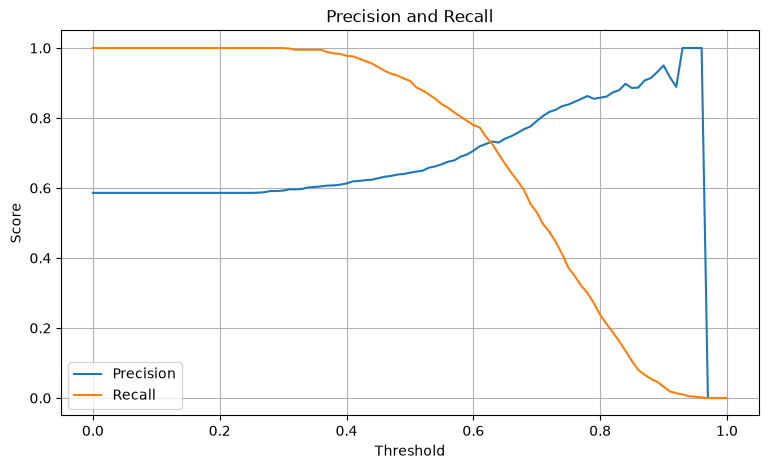

Best threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458
Difference: 0.007502647993409384

Q3 OPTIONS:
 threshold  precision   recall  difference
      0.43   0.622517 0.962457    0.339941
      0.63   0.732759 0.725256    0.007503
      0.73   0.823344 0.445392    0.377951
      0.83   0.879630 0.162116    0.717514

Q3 ANSWER: 0.63


In [55]:
thresholds = np.arange(0.0, 1.001, 0.01)

rows = []

for threshold in thresholds:
    y_pred = (val_probs >= threshold).astype(int)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision,
        "recall": recall,
        "difference": abs(precision - recall)
    })

metrics_df = pd.DataFrame(rows)

# Для графика
plt.figure(figsize=(9, 5))
plt.plot(
    metrics_df["threshold"],
    metrics_df["precision"],
    label="Precision"
)
plt.plot(
    metrics_df["threshold"],
    metrics_df["recall"],
    label="Recall"
)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall")
plt.legend()
plt.grid(True)
plt.show()

valid = metrics_df[
    (metrics_df["precision"] != 0) |
    (metrics_df["recall"] != 0)
]

best_row = valid.loc[valid["difference"].idxmin()]

print("Best threshold:", best_row["threshold"])
print("Precision:", best_row["precision"])
print("Recall:", best_row["recall"])
print("Difference:", best_row["difference"])

options = [0.43, 0.63, 0.73, 0.83]

option_rows = metrics_df[
    metrics_df["threshold"].isin(options)
]

print("\nQ3 OPTIONS:")
print(
    option_rows[
        ["threshold", "precision", "recall", "difference"]
    ].to_string(index=False)
)

q3_answer = option_rows.loc[
    option_rows["difference"].idxmin(), "threshold"
]

print("\nQ3 ANSWER:", q3_answer)

In [56]:
denominator = (
    metrics_df["precision"] + metrics_df["recall"]
)

metrics_df["f1"] = np.where(
    denominator > 0,
    2 * metrics_df["precision"] * metrics_df["recall"]
    / denominator,
    0.0
)

max_f1 = metrics_df["f1"].max()

best_thresholds = metrics_df[
    np.isclose(metrics_df["f1"], max_f1)
]

print("Maximum F1:", max_f1)
print("\nThresholds with maximum F1:")
print(
    best_thresholds[
        ["threshold", "precision", "recall", "f1"]
    ].to_string(index=False)
)

options = [0.21, 0.41, 0.61, 0.81]

option_rows = metrics_df[
    metrics_df["threshold"].isin(options)
]

print("\nQ4 OPTIONS:")
print(
    option_rows[
        ["threshold", "precision", "recall", "f1"]
    ].to_string(index=False)
)

q4_answer = option_rows.loc[
    option_rows["f1"].idxmax(), "threshold"
]

print("\nQ4 ANSWER:", q4_answer)

Maximum F1: 0.7576158940397352

Thresholds with maximum F1:
 threshold  precision   recall       f1
      0.41   0.619048 0.976109 0.757616

Q4 OPTIONS:
 threshold  precision   recall       f1
      0.21   0.586000 1.000000 0.738966
      0.41   0.619048 0.976109 0.757616
      0.61   0.719048 0.773038 0.745066
      0.81   0.861111 0.211604 0.339726

Q4 ANSWER: 0.41


In [57]:
def cv_auc_scores(data, C):
    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    scores = []

    for train_idx, val_idx in kf.split(data):
        fold_train = data.iloc[train_idx]
        fold_val = data.iloc[val_idx]

        y_fold_train = fold_train["converted"].to_numpy()
        y_fold_val = fold_val["converted"].to_numpy()

        x_fold_train = fold_train.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        x_fold_val = fold_val.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        fold_dv = DictVectorizer(sparse=True)

        X_fold_train = fold_dv.fit_transform(
            x_fold_train
        ).tocsr()

        X_fold_val = fold_dv.transform(
            x_fold_val
        ).tocsr()

        # Приводим индексы к int32
        for X in (X_fold_train, X_fold_val):
            X.indices = X.indices.astype(np.int32)
            X.indptr = X.indptr.astype(np.int32)

            # Проверяем фактические типы
            assert X.indices.dtype == np.int32
            assert X.indptr.dtype == np.int32

        fold_model = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        fold_model.fit(X_fold_train, y_fold_train)

        probabilities = fold_model.predict_proba(
            X_fold_val
        )[:, 1]

        scores.append(
            roc_auc_score(y_fold_val, probabilities)
        )

    return np.array(scores)

In [58]:
scores = cv_auc_scores(df_full_train, C=1.0)

print("Fold AUC scores:", np.round(scores, 6))
print("Standard deviation:", np.std(scores))
print("Q5 ANSWER:", round(np.std(scores), 3))

Fold AUC scores: [0.73056  0.729573 0.736343 0.741245 0.720914]
Standard deviation: 0.006853233151022138
Q5 ANSWER: 0.007


In [59]:
C_values = [0.000001, 0.001, 1]

cv_results = []

for C in C_values:
    scores = cv_auc_scores(df_full_train, C=C)

    mean_auc = scores.mean()
    std_auc = scores.std()

    cv_results.append({
        "C": C,
        "mean_auc": mean_auc,
        "std_auc": std_auc
    })

results_df = pd.DataFrame(cv_results)

results_df["mean_rounded"] = results_df["mean_auc"].round(3)
results_df["std_rounded"] = results_df["std_auc"].round(3)

print(results_df.to_string(index=False))

results_df = results_df.sort_values(
    by=["mean_rounded", "std_rounded", "C"],
    ascending=[False, True, True]
)

q6_answer = results_df.iloc[0]["C"]

print("\nQ6 ANSWER — Best C:", q6_answer)

       C  mean_auc  std_auc  mean_rounded  std_rounded
0.000001  0.616734 0.018670         0.617        0.019
0.001000  0.749172 0.009996         0.749        0.010
1.000000  0.731727 0.006853         0.732        0.007

Q6 ANSWER — Best C: 0.001
